In [1]:
from pathlib import Path

ROOT = Path("/root/autodl-tmp/medical_data")

MENINGIOMA_ROOT = ROOT / "meningioma"
HEMORRHAGE_ROOT = ROOT / "brain_hemorrhage"
OUTPUT_ROOT = ROOT / "hemorrhage_vs_tumor_ct"

print("脑膜瘤目录：", MENINGIOMA_ROOT.exists())
print("脑出血目录：", HEMORRHAGE_ROOT.exists())

subjects = sorted(MENINGIOMA_ROOT.glob("sub-*"))

print("脑膜瘤患者数：", len(subjects))

for subject in subjects:
    ct_file = subject / "CT-BRAIN.nii.gz"
    mr_file = subject / "CE-T1W.nii.gz"

    print(
        subject.name,
        "CT =", ct_file.exists(),
        "MRI =", mr_file.exists()
    )

脑膜瘤目录： True
脑出血目录： True
脑膜瘤患者数： 20
sub-01 CT = True MRI = True
sub-02 CT = True MRI = True
sub-03 CT = True MRI = True
sub-04 CT = True MRI = True
sub-05 CT = True MRI = True
sub-06 CT = True MRI = True
sub-07 CT = True MRI = True
sub-08 CT = True MRI = True
sub-09 CT = True MRI = True
sub-10 CT = True MRI = True
sub-11 CT = True MRI = True
sub-12 CT = True MRI = True
sub-13 CT = True MRI = True
sub-14 CT = True MRI = True
sub-15 CT = True MRI = True
sub-16 CT = True MRI = True
sub-17 CT = True MRI = True
sub-18 CT = True MRI = True
sub-19 CT = True MRI = True
sub-20 CT = True MRI = True


In [2]:
!pip install -q nibabel ipywidgets


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

In [4]:
def load_volume(path):
    image = nib.as_closest_canonical(
        nib.load(str(path))
    )
    return np.asarray(
        image.dataobj,
        dtype=np.float32
    )


def show_subject_slice(subject_name, z):
    subject_dir = (
        MENINGIOMA_ROOT /
        subject_name
    )

    ct = load_volume(
        subject_dir / "CT-BRAIN.nii.gz"
    )

    mr = load_volume(
        subject_dir / "CE-T1W.nii.gz"
    )

    z = int(np.clip(
        z,
        0,
        min(ct.shape[2], mr.shape[2]) - 1
    ))

    ct_slice = np.rot90(ct[:, :, z])
    mr_slice = np.rot90(mr[:, :, z])

    # CT脑窗：窗位40，窗宽80
    ct_display = np.clip(
        ct_slice,
        0,
        80
    )

    # MRI按百分位显示
    nonzero = mr_slice[mr_slice > 0]

    if len(nonzero):
        low, high = np.percentile(
            nonzero,
            [1, 99]
        )
    else:
        low, high = 0, 1

    figure, axes = plt.subplots(
        1,
        2,
        figsize=(10, 5)
    )

    axes[0].imshow(
        mr_slice,
        cmap="gray",
        vmin=low,
        vmax=high
    )
    axes[0].set_title(
        f"{subject_name} MRI, z={z}"
    )

    axes[1].imshow(
        ct_display,
        cmap="gray",
        vmin=0,
        vmax=80
    )
    axes[1].set_title(
        f"{subject_name} CT-BRAIN, z={z}"
    )

    for axis in axes:
        axis.axis("off")

    plt.tight_layout()
    plt.show()

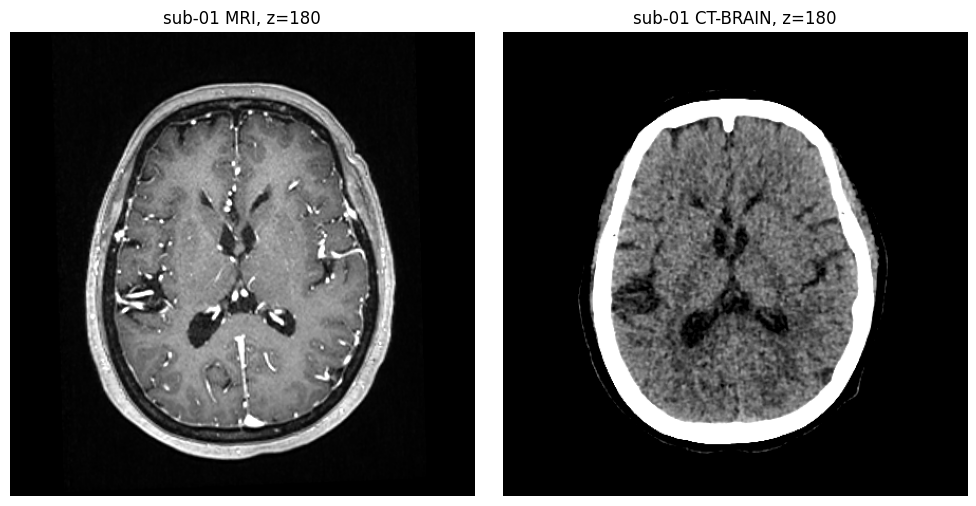

In [5]:
show_subject_slice(
    "sub-01",
    180
)

In [6]:
import ipywidgets as widgets

subject_widget = widgets.Dropdown(
    options=[
        subject.name
        for subject in subjects
    ],
    description="患者："
)

slice_widget = widgets.IntSlider(
    value=180,
    min=0,
    max=380,
    step=1,
    description="切片：",
    continuous_update=False
)

widgets.interact(
    show_subject_slice,
    subject_name=subject_widget,
    z=slice_widget
)

interactive(children=(Dropdown(description='患者：', options=('sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', '…

<function __main__.show_subject_slice(subject_name, z)>

In [8]:
from pathlib import Path
import zipfile

ROOT = Path(
    "/root/autodl-tmp/medical_data/"
    "CTBrain-TumorSegmentation-AnnotationProject-main"
)

IMAGE_DIR = ROOT / "raw__data" / "50_ct_brain_raw_data_png"
MASK_ROOT = ROOT / "annotated_data" / "segmentation_masks"

MASK_ZIP = (
    MASK_ROOT /
    "50_ct_brain_tumor_annotated_in_segmentation_mask_CLASS-png_format.zip"
)

with zipfile.ZipFile(MASK_ZIP, "r") as z:
    z.extractall(MASK_ROOT)

MASK_DIR = (
    MASK_ROOT /
    "50_ct_brain_tumor_annotated_in_segmentation_mask_CLASS-png_format"
)

images = sorted(IMAGE_DIR.glob("*.png"))
masks = sorted(MASK_DIR.glob("*.png"))

print("CT 原图数量：", len(images))
print("肿瘤掩膜数量：", len(masks))
print("原图目录：", IMAGE_DIR)
print("掩膜目录：", MASK_DIR)

CT 原图数量： 50
肿瘤掩膜数量： 50
原图目录： /root/autodl-tmp/medical_data/CTBrain-TumorSegmentation-AnnotationProject-main/raw__data/50_ct_brain_raw_data_png
掩膜目录： /root/autodl-tmp/medical_data/CTBrain-TumorSegmentation-AnnotationProject-main/annotated_data/segmentation_masks/50_ct_brain_tumor_annotated_in_segmentation_mask_CLASS-png_format


In [9]:
from PIL import Image
import numpy as np
import pandas as pd

records = []

for image_path in sorted(IMAGE_DIR.glob("*.png")):
    mask_path = MASK_DIR / image_path.name

    if not mask_path.exists():
        records.append({
            "file": image_path.name,
            "status": "缺少掩膜",
            "mask_pixels": 0,
            "mask_ratio": 0
        })
        continue

    image = np.array(Image.open(image_path).convert("RGB"))
    mask = np.array(Image.open(mask_path))

    # 兼容彩色或单通道掩膜
    if mask.ndim == 3:
        mask_binary = np.any(mask > 0, axis=2)
    else:
        mask_binary = mask > 0

    mask_pixels = int(mask_binary.sum())
    mask_ratio = mask_pixels / mask_binary.size

    records.append({
        "file": image_path.name,
        "status": "正常" if mask_pixels > 0 else "空掩膜",
        "image_shape": str(image.shape),
        "mask_shape": str(mask.shape),
        "mask_pixels": mask_pixels,
        "mask_ratio": mask_ratio
    })

mask_check = pd.DataFrame(records)

print("=" * 60)
print("肿瘤 CT 标注检查")
print("=" * 60)
print("原图数量：", len(list(IMAGE_DIR.glob("*.png"))))
print("掩膜数量：", len(list(MASK_DIR.glob("*.png"))))
print("正常标注：", (mask_check["status"] == "正常").sum())
print("空掩膜：", (mask_check["status"] == "空掩膜").sum())
print("缺少掩膜：", (mask_check["status"] == "缺少掩膜").sum())
print("=" * 60)

display(mask_check)

肿瘤 CT 标注检查
原图数量： 50
掩膜数量： 50
正常标注： 50
空掩膜： 0
缺少掩膜： 0


,file,status,image_shape,mask_shape,mask_pixels,mask_ratio
0,ct_tumor (1).png,正常,"(957, 821, 3)","(957, 821, 3)",62545,0.079604
1,ct_tumor (10).png,正常,"(288, 231, 3)","(288, 231, 3)",3737,0.056172
2,ct_tumor (11).png,正常,"(285, 247, 3)","(285, 247, 3)",10264,0.145806
3,ct_tumor (12).png,正常,"(635, 540, 3)","(635, 540, 3)",29038,0.084684
4,ct_tumor (13).png,正常,"(559, 531, 3)","(559, 531, 3)",20086,0.067669
5,ct_tumor (14).png,正常,"(601, 504, 3)","(601, 504, 3)",21637,0.071432
6,ct_tumor (15).png,正常,"(612, 505, 3)","(612, 505, 3)",33329,0.107840
7,ct_tumor (16).png,正常,"(495, 435, 3)","(495, 435, 3)",13604,0.063179
8,ct_tumor (17).png,正常,"(491, 426, 3)","(491, 426, 3)",19921,0.095240
9,ct_tumor (18).png,正常,"(437, 349, 3)","(437, 349, 3)",7464,0.048940


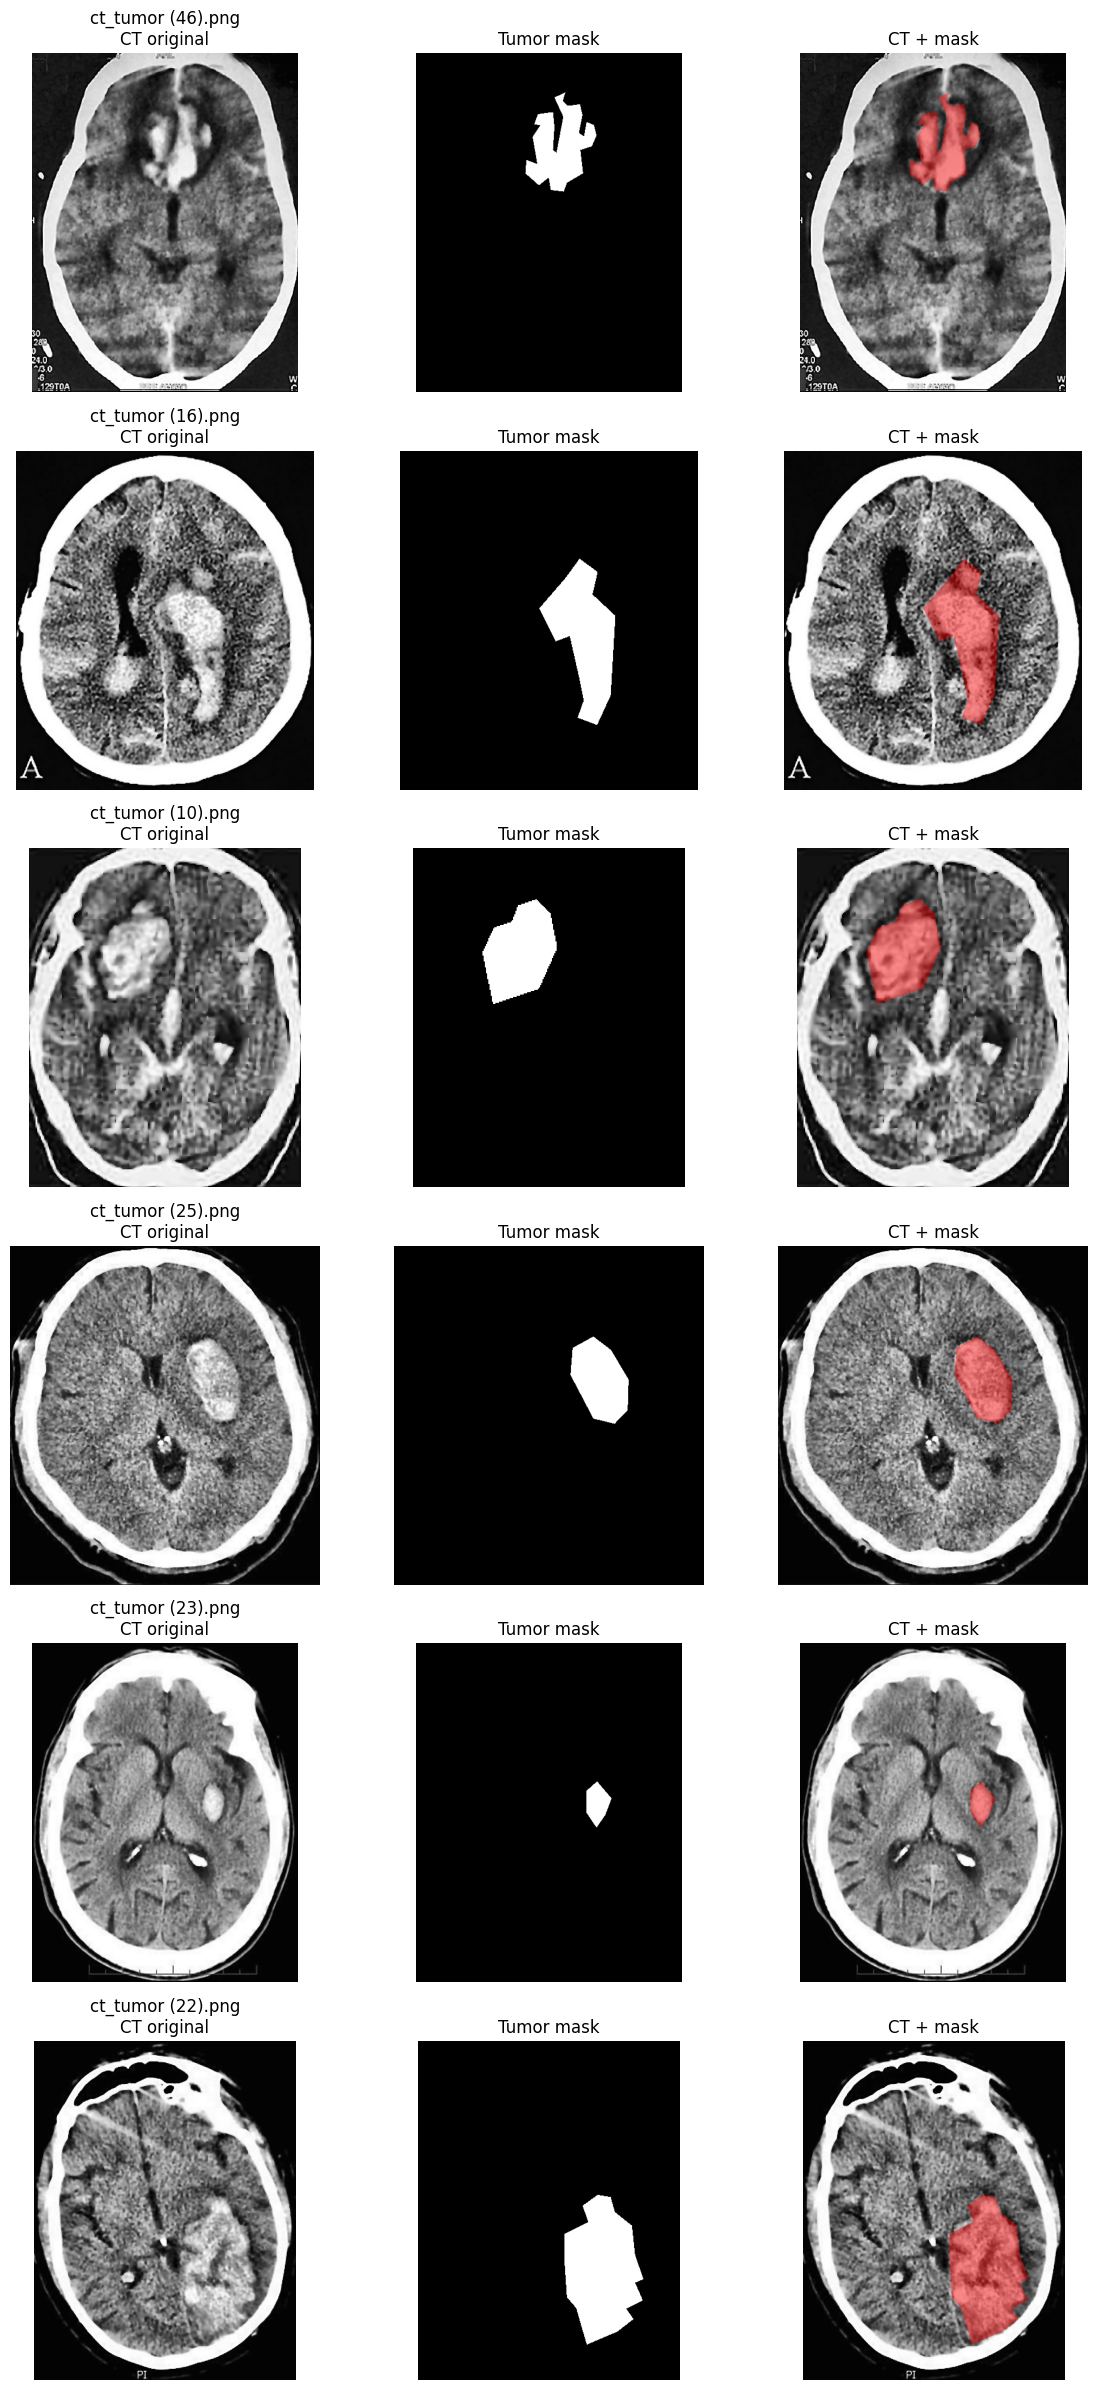

In [10]:
import matplotlib.pyplot as plt
import random

random.seed(42)

valid_names = mask_check.loc[
    mask_check["status"] == "正常",
    "file"
].tolist()

sample_names = random.sample(
    valid_names,
    min(6, len(valid_names))
)

fig, axes = plt.subplots(
    len(sample_names),
    3,
    figsize=(12, 4 * len(sample_names))
)

if len(sample_names) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, filename in enumerate(sample_names):
    image = np.array(
        Image.open(IMAGE_DIR / filename).convert("RGB")
    )

    mask = np.array(
        Image.open(MASK_DIR / filename)
    )

    if mask.ndim == 3:
        mask_binary = np.any(mask > 0, axis=2)
    else:
        mask_binary = mask > 0

    overlay = image.copy()

    # 标注区域覆盖成红色
    red = np.zeros_like(image)
    red[..., 0] = 255

    alpha = 0.45
    overlay[mask_binary] = (
        image[mask_binary] * (1 - alpha) +
        red[mask_binary] * alpha
    ).astype(np.uint8)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{filename}\nCT original")

    axes[row, 1].imshow(mask_binary, cmap="gray")
    axes[row, 1].set_title("Tumor mask")

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("CT + mask")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
from pathlib import Path
from collections import Counter

HEMORRHAGE_ROOT = Path(
    "/root/autodl-tmp/medical_data/brain_hemorrhage"
)

image_suffixes = {".png", ".jpg", ".jpeg", ".bmp"}

hemorrhage_files = [
    p for p in HEMORRHAGE_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in image_suffixes
]

print("=" * 60)
print("脑出血数据检查")
print("=" * 60)
print("图片总数：", len(hemorrhage_files))

print("\n各目录图片数量：")
folder_counts = Counter(
    str(p.parent.relative_to(HEMORRHAGE_ROOT))
    for p in hemorrhage_files
)

for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count}")

print("\nCSV 文件：")
csv_files = list(HEMORRHAGE_ROOT.rglob("*.csv"))

for path in csv_files:
    print(path)

print("\n前20张图片：")
for path in hemorrhage_files[:20]:
    print(path.relative_to(HEMORRHAGE_ROOT))

脑出血数据检查
图片总数： 200

各目录图片数量：
test/negative: 15
test/positive: 15
train/negative: 70
train/positive: 70
val/negative: 15
val/positive: 15

CSV 文件：

前20张图片：
train/negative/142.png
train/negative/141.png
train/negative/191.png
train/negative/109.png
train/negative/165.png
train/negative/150.png
train/negative/101.png
train/negative/170.png
train/negative/115.png
train/negative/178.png
train/negative/173.png
train/negative/110.png
train/negative/155.png
train/negative/156.png
train/negative/172.png
train/negative/145.png
train/negative/148.png
train/negative/192.png
train/negative/176.png
train/negative/137.png
